# 05 - Mesin kebijakan limit & simulasi dampak (statis vs dinamis)
Menjawab dua hal inti proposal yang sebelumnya belum ada:
1. **Mesin kebijakan** (`limit/policy.py`): tier T1-T5, aturan §4.3, kasus tepi §4.4, dan alur keputusan §7 (`rec_tier = MIN(ceiling, demand, current + 1)`).
2. **Bukti dampak** (§2.3 / §10): apakah limit dinamis mengurangi penolakan transaksi sah **tanpa** menambah eksposur fraud?

Alur: (1) tabel aturan -> kode, (2) uji unit tiap aturan, (3) simulasi 10.000 nasabah, (4) uji sensitivitas asumsi, (5) kesimpulan & keterbatasan.

**Data simulasi:** `data/sim` (seed 9, 10.000 nasabah, ID `S...`), dibuat khusus dan terpisah dari DEV/TEST. Model scorecard dan forecast dilatih di DEV (notebook 04); model fraud adalah bundel juara (notebook 02c).

## 1. Aturan proposal -> implementasi
| Proposal | Aturan | Implementasi di `policy.py` |
|---|---|---|
| §4.2 | T2: skor >= batas, 3 bulan inflow rutin, tanpa dispute | `ceiling_tier` (rantai syarat T2 -> T5) |
| §4.2 | T3: forecast > 60% cap T2 dan 6 bulan di T2; T4: re-KYC <= 24 bln; T5: review manual + re-KYC tahunan | `demand_tier`, `months_at_prior_tier`, `kyc_max_months`, `t5_manual_review` |
| §4.3 | maks satu tier naik per siklus | `rec = MIN(ceiling, demand, tier + 1)` |
| §4.3 | cooldown 7 hari antar perubahan | `cooldown_days` |
| §4.3 | kenaikan: ditawarkan, diterima nasabah, berlaku 24 jam kemudian | `OFFER_INCREASE` -> `accepted_day` -> `APPLY_INCREASE` setelah `increase_delay_days` |
| §4.3 | hysteresis: turun hanya bila rekomendasi lebih rendah 3 evaluasi berturut-turut, kecuali fraud gate | `consec_lower`, `lower_needed` |
| §4.3 | cold start: tier onboarding dipertahankan, model baru boleh menaikkan setelah 6 bulan data, tidak pernah menurunkan | `min_tenure_months`, lantai `baseline` |
| §4.3 | nasabah boleh menurunkan limit sendiri, menaikkan hanya lewat penawaran | `self_cap` |
| §4.3 | reviewer boleh mem-pin tier 6 bulan (banding) | `pinned_until` |
| §4.4 | dormant tidak pernah menurunkan tier | `active_recent` |
| §4.4 | batch gagal / skor basi: tidak ada perubahan otomatis | `feature_ok` (False -> KEEP) |
| §4.4 | **lantai non-negosiasi:** tidak pernah lebih buruk dari tier statis kecuali fraud gate menyala | lantai `baseline` pada setiap penurunan |
| §6.3 | gate menyala -> tidak ada kenaikan; hit (H) -> hold (dan turun satu tier bila di atas baseline) | `gate_block`, `gate_hold`, `GATE_STEP_DOWN` |
| §4.4 | hold/seasonal: forecast memakai kalender | fitur `ramadan_overlap`, `school_overlap` di forecast (notebook 04) |

In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")      # notebooks use paths relative to the project root
print("working directory:", os.getcwd())

In [1]:
import os, sys, json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd()); sys.path.insert(0, "limit")
from policy import PolicyEngine, A, ACTIONS, CAP, DEFAULT_POLICY
import simulate as SM
cuts = json.load(open("limit/artifacts/tier_cuts.json"))["score_cut"]; print("batas poin tier (T1..T5):", cuts)

batas poin tier (T1..T5): [0.0, 611.8, 629.5, 648.0, 664.8]


## 2. Uji unit: setiap aturan didemonstrasikan pada kasus kecil
Setiap uji membuat satu atau beberapa nasabah, menjalankan `step()` hari demi hari, dan memastikan aksi sesuai aturan. Uji gagal = notebook berhenti.

In [2]:
def mk(baseline, n=1, **over):
    return PolicyEngine(np.full(n, baseline), {"score_cut": tuple(cuts), **over})
def inp(n=1, **kw):
    base = dict(score=np.full(n, 700.0), tenure_months=np.full(n, 24.0), regular_windows=np.full(n, 3), disputes_90=np.zeros(n), kyc_age_months=np.full(n, 6.0), forecast=np.full(n, 40e6),
                feature_ok=np.ones(n, bool), active_recent=np.ones(n, bool), gate_block=np.zeros(n, bool), gate_hold=np.zeros(n, bool))
    base.update({k: np.asarray(v).reshape(-1) if np.ndim(v) else np.full(n, v) for k, v in kw.items()}); return base
def day(e, t, accept=None, **kw): 
    act, tgt, prev = e.step(t, inp(len(e.tier), **kw), None if accept is None else np.array([accept])); return ACTIONS[act[0]]
rows = []
def case(name, rule, ok): rows.append(dict(uji=name, aturan=rule, hasil="LULUS" if ok else "GAGAL")); assert ok, name

e = mk(2); case("naik satu tier saja", "§4.3 maks satu tier per siklus", day(e, 1000) == "OFFER_INCREASE" and e.offer_to[0] == 3)
e = mk(2); day(e, 1000); case("tak ada penawaran kedua selagi pending", "§4.3", day(e, 1001) == "KEEP")
e = mk(2); day(e, 1000); a1 = day(e, 1001, accept=True); case("tidak berlaku pada hari penerimaan (jeda 24 jam)", "§4.3 jeda 24 jam", a1 == "KEEP" and e.tier[0] == 2)
e = mk(2); day(e, 1000); day(e, 1001, accept=True); a = day(e, 1002); case("kenaikan diterapkan sesudah jeda", "§4.3", a == "APPLY_INCREASE" and e.tier[0] == 3)
e = mk(2); day(e, 1000); day(e, 1001, accept=True); a = day(e, 1002, gate_block=True); case("gate membatalkan kenaikan yang pending", "§6.3 re-cek gate", a == "CANCEL_OFFER" and e.tier[0] == 2)
e = mk(2); e.last_change[:] = 998; case("cooldown 7 hari blokir perubahan", "§4.3", day(e, 1000) == "KEEP" and day(e, 1005) == "OFFER_INCREASE")
e = mk(2); case("nasabah baru (<12 bln) tidak dievaluasi", "§4.3 cold start", day(e, 1000, tenure_months=8) == "KEEP")
e = mk(2); case("data tidak lengkap -> abstain", "§4.4 thin data / batch gagal", day(e, 1000, feature_ok=False) == "KEEP")
e = mk(2); case("gate menyala -> tidak ada kenaikan", "§6.3", day(e, 1000, gate_block=True) == "KEEP")
e = mk(2); case("hold bila hit (H) pada tier baseline", "§6.3 (H)", day(e, 1000, gate_hold=True, gate_block=True) == "HOLD" and e.tier[0] == 2)
e = mk(2); e.tier[:] = 3; case("hit (H) di atas baseline -> turun satu tier seketika", "§4.3 gate", day(e, 1000, gate_hold=True, gate_block=True) == "GATE_STEP_DOWN" and e.tier[0] == 2)
e = mk(2, lower_needed=3); e.tier[:] = 3; e.tier_since[:] = 900; e.last_change[:] = 900
acts = [day(e, 1000 + i, score=cuts[1] - 1, regular_windows=0) for i in range(3)]; case("turun hanya setelah N evaluasi berturut-turut (hysteresis, N=3 literal proposal)", "§4.3", acts[:2] == ["KEEP", "KEEP"] and acts[2] == "STEP_DOWN" and e.tier[0] == 2)
e = mk(2); e.tier[:] = 3; e.tier_since[:] = 900; e.last_change[:] = 900
acts = [day(e, 1000 + i, score=cuts[1] - 1, regular_windows=0) for i in range(13)]; a14 = day(e, 1013, score=cuts[1] - 1, regular_windows=0); case("default 14 evaluasi: tidak turun sebelum hari ke-14", "§4.3 (disetel: evaluasi harian)", "STEP_DOWN" not in acts and a14 == "STEP_DOWN")
e = mk(2, lower_needed=3); e.tier[:] = 3; e.tier_since[:] = 900; e.last_change[:] = 900
for i in range(2): day(e, 1000 + i, score=cuts[1] - 1, regular_windows=0)
day(e, 1002); case("satu evaluasi baik mereset hitungan turun", "§4.3 hysteresis", e.consec_lower[0] == 0)
e = mk(2); e.tier[:] = 2; acts = [day(e, 1000 + i, score=0.0, regular_windows=0) for i in range(10)]; case("tidak pernah turun di bawah tier baseline", "§4.4 lantai", e.tier[0] == 2 and "STEP_DOWN" not in acts)
e = mk(3); e.tier[:] = 4; e.tier_since[:] = 900; e.last_change[:] = 900; acts = [day(e, 1000 + i, score=0.0, regular_windows=0, active_recent=False) for i in range(6)]; case("dormant tidak menurunkan tier", "§4.4 dormant", "STEP_DOWN" not in acts and e.tier[0] == 4)
e = mk(2); e.set_self_cap(0, 2); case("limit pilihan nasabah menjadi batas atas penawaran", "§4.3 override", day(e, 1000) == "KEEP")
e = mk(3); e.tier[:] = 4; e.set_self_cap(0, 2); day(e, 1000); case("menurunkan sendiri berlaku seketika", "§4.3 override", e.tier[0] == 2)
e = mk(2); e.pin(0, 5000); case("tier yang di-pin reviewer tidak diubah model", "§4.4 banding", day(e, 1000) == "KEEP")
e = mk(3); e.tier[:] = 3; e.tier_since[:] = 990; case("masuk T4 butuh 6 bulan di T3", "§4.2 months at prior tier", day(e, 1000, forecast=80e6) == "KEEP")
e = mk(3); e.tier[:] = 3; e.tier_since[:] = 100; case("masuk T4 setelah 6 bulan di T3", "§4.2", day(e, 1000, forecast=80e6) == "OFFER_INCREASE" and e.offer_to[0] == 4)
e = mk(3); e.tier[:] = 3; e.tier_since[:] = 100; case("T4 butuh re-KYC <= 24 bulan", "§4.2 re-KYC", day(e, 1000, forecast=80e6, kyc_age_months=40) == "KEEP")
e = mk(4); e.tier[:] = 4; e.tier_since[:] = 100; case("masuk T5 hanya lewat antrean review manual", "§4.2", day(e, 1000, forecast=190e6, score=999) == "REVIEW_QUEUE")
e = mk(2); case("kenaikan butuh kebutuhan (forecast) yang terbukti", "§7 demand_tier", day(e, 1000, forecast=3e6) == "KEEP")
pd.DataFrame(rows)

,uji,aturan,hasil
0,naik satu tier saja,§4.3 maks satu tier per siklus,LULUS
1,tak ada penawaran kedua selagi pending,§4.3,LULUS
2,tidak berlaku pada hari penerimaan (jeda 24 jam),§4.3 jeda 24 jam,LULUS
3,kenaikan diterapkan sesudah jeda,§4.3,LULUS
4,gate membatalkan kenaikan yang pending,§6.3 re-cek gate,LULUS
5,cooldown 7 hari blokir perubahan,§4.3,LULUS
6,nasabah baru (<12 bln) tidak dievaluasi,§4.3 cold start,LULUS
7,data tidak lengkap -> abstain,§4.4 thin data / batch gagal,LULUS
8,gate menyala -> tidak ada kenaikan,§6.3,LULUS
9,hold bila hit (H) pada tier baseline,§6.3 (H),LULUS


## 3. Simulasi 10.000 nasabah selama 364 hari
**Cara kerja (open-loop replay):**
* Fitur nasabah diambil dari dunia statis; mesin kebijakan memutuskan tier tiap hari (batch 02:00 memakai fitur kemarin).
* Hasil dihitung ulang di bawah limit dinamis dengan logika realisasi transfer yang sama dengan generator data: transfer yang diinginkan dipotong oleh batas, selisihnya = **ditolak karena limit**.
* Skenario: **S0** limit statis tanpa gate (kondisi hari ini); **S1** limit statis + fraud gate; **S2** limit dinamis + fraud gate (usulan proposal).
* Asumsi perilaku: 70% penawaran diterima (1-4 hari); sebuah hold pada hari fraud mencegah 50% outflow hari itu (deteksi tidak instan); hold pada nasabah sah dihitung sebagai gesekan (*false hold*).
* **Keterbatasan:** perilaku nasabah tidak bereaksi terhadap limit baru (tanpa umpan balik), dan skor dihitung dari fitur dunia statis.

In [3]:
import time; t0 = time.time()
prep = SM.prepare(None, 1, "data/sim"); print(f"persiapan data+model: {time.time() - t0:.0f}s | nasabah {prep['n']:,}")
out, mig, ctx = SM.run(prep, seed=1); print(f"simulasi kebijakan: {time.time() - t0:.0f}s total")
def per1k(d, k): return d[k] / prep["n"] * 1000
rows = {}
for sc, name in (("S0_static", "S0 statis, tanpa gate"), ("S1_static_gate", "S1 statis + gate"), ("S2_dynamic_gate", "S2 dinamis + gate")):
    d = out[sc]; rows[name] = {"transaksi sah ditolak limit (per 1.000 nasabah/tahun)": per1k(d, "declined_events"), "nasabah sah terdampak penolakan (%)": 100 * d["customers_with_decline"] / prep["n"],
        "nilai tertolak (Rp miliar)": d["declined_amount"] / 1e9, "volume sah terselesaikan (Rp miliar)": d["legit_volume"] / 1e9, "outflow fraud lolos (Rp juta)": d["fraud_outflow"] / 1e6,
        "hari fraud ditahan": d["fraud_days_held"], "false hold (per 1.000 nasabah/tahun)": per1k(d, "false_holds")}
res = pd.DataFrame(rows).T; res.round(2).T

persiapan data+model: 12s | nasabah 10,000


simulasi kebijakan: 13s total


,"S0 statis, tanpa gate",S1 statis + gate,S2 dinamis + gate
transaksi sah ditolak limit (per 1.000 nasabah/tahun),2327.00,2327.00,1574.20
nasabah sah terdampak penolakan (%),31.96,31.96,25.19
nilai tertolak (Rp miliar),1505.56,1505.56,1295.63
volume sah terselesaikan (Rp miliar),3797.88,3797.88,4007.82
outflow fraud lolos (Rp juta),7239.33,4105.57,4172.79
hari fraud ditahan,0.00,846.00,846.00
false hold (per 1.000 nasabah/tahun),0.00,80.80,80.80


In [4]:
s0, s1, s2 = out["S0_static"], out["S1_static_gate"], out["S2_dynamic_gate"]
delta = pd.Series({"penolakan sah turun (S2 vs S0)": 1 - s2["declined_events"] / s0["declined_events"], "nasabah terdampak turun": 1 - s2["customers_with_decline"] / s0["customers_with_decline"],
                   "volume sah terselesaikan naik": s2["legit_volume"] / s0["legit_volume"] - 1, "fraud lolos turun, gate saja (S1 vs S0)": 1 - s1["fraud_outflow"] / s0["fraud_outflow"],
                   "fraud lolos berubah karena limit dinamis (S2 vs S1)": s2["fraud_outflow"] / s1["fraud_outflow"] - 1, "cap rata-rata pada hari pertama fraud (statis -> dinamis, Rp juta)": None})
print((delta.dropna() * 100).round(1).astype(str) + " %")
print("cap rata-rata pada hari pertama fraud (Rp juta):", {k: round(v / 1e6, 1) for k, v in out["fraud_cap_on_first_day"].items() if k != "n"}, "| nasabah fraud:", out["fraud_cap_on_first_day"]["n"])

penolakan sah turun (S2 vs S0)                         32.4 %
nasabah terdampak turun                                21.2 %
volume sah terselesaikan naik                           5.5 %
fraud lolos turun, gate saja (S1 vs S0)                43.3 %
fraud lolos berubah karena limit dinamis (S2 vs S1)     1.6 %
dtype: object
cap rata-rata pada hari pertama fraud (Rp juta): {'static': 29.2, 'dynamic': 34.4} | nasabah fraud: 300


### Sumber pemicu: model vs aturan §6.3 (H)
Setiap sumber diukur sendiri: berapa hari fraud yang tertandai dibanding hari sah yang tertandai (presisi). Ini menguji apakah aturan deterministik proposal layak menjadi pemicu *hold* otomatis.
**Hasil percobaan awal (hold dari model + dua aturan):** presisi night velocity 2,8% dan outflow/balance 0,25%, sehingga ~795 hold salah per 1.000 nasabah-tahun. **Keputusan (G13):** dua aturan itu diubah menjadi pemicu *step-up auth* dan blokir-kenaikan; hold hanya dipicu oleh skor model. Semua angka di bagian ini sudah memakai keputusan itu.

In [5]:
hs = pd.DataFrame(out["hold_sources_dynamic"]).T; hs["presisi"] = hs.fraud_days / (hs.fraud_days + hs.legit_days); hs["hari sah ditahan / 1.000 nasabah-tahun"] = hs.legit_days / prep["n"] * 1000
hs.round(3)

,legit_days,fraud_days,presisi,hari sah ditahan / 1.000 nasabah-tahun
model_high_risk,808,846,0.511,80.8
rule_night_velocity,2865,82,0.028,286.5
rule_outflow_balance,3191,8,0.003,319.1
model_suspicious,13701,144,0.010,1370.1


In [6]:
print("Prompt step-up pada hari sah (aturan night/balance + pita suspicious): per 1.000 nasabah-tahun:", round(out["stepup_prompts"]["dynamic_per_1000"], 1), "| hari fraud yang tercakup:", out["stepup_prompts"]["fraud_days_covered"])

Prompt step-up pada hari sah (aturan night/balance + pita suspicious): per 1.000 nasabah-tahun: 1903.3 | hari fraud yang tercakup: 228


## Migrasi tier dan aktivitas kebijakan

In [7]:
print("Migrasi tier (baris = tier awal, kolom = tier akhir):"); display(mig)
act = pd.Series(out["actions"]).drop("KEEP"); print("Aksi kebijakan (jumlah nasabah-hari):", act.to_dict())
summ = pd.Series({"nasabah yang pernah naik tier (%)": 100 * out["customers_ever_increased"] / prep["n"], "nasabah di bawah tier baseline (harus 0)": out["customers_ever_below_baseline"],
                  "perubahan tier per nasabah-tahun": out["tier_changes_per_customer_year"], "median hari sampai kenaikan pertama": out["median_days_to_first_increase"],
                  "nasabah masuk antrean review T5": out["customers_review_queue"], "nasabah pernah terkena hold": out["customers_ever_held"]})
assert out["customers_ever_below_baseline"] == 0, "lantai baseline dilanggar"
summ.round(2)

Migrasi tier (baris = tier awal, kolom = tier akhir):


end,1,2,3,4,5
baseline,,,,,
1,3054,919,148,0,0
2,0,2972,508,121,0
3,0,0,1209,227,0
4,0,0,0,657,0
5,0,0,0,0,185


Aksi kebijakan (jumlah nasabah-hari): {'OFFER_INCREASE': 15785, 'APPLY_INCREASE': 4888, 'STEP_DOWN': 2461, 'HOLD': 1468, 'CANCEL_OFFER': 234, 'EXPIRE_OFFER': 10146, 'REVIEW_QUEUE': 18198, 'GATE_STEP_DOWN': 181}


nasabah yang pernah naik tier (%)            31.90
nasabah di bawah tier baseline (harus 0)      0.00
perubahan tier per nasabah-tahun              0.75
median hari sampai kenaikan pertama          25.00
nasabah masuk antrean review T5             253.00
nasabah pernah terkena hold                 721.00
dtype: float64

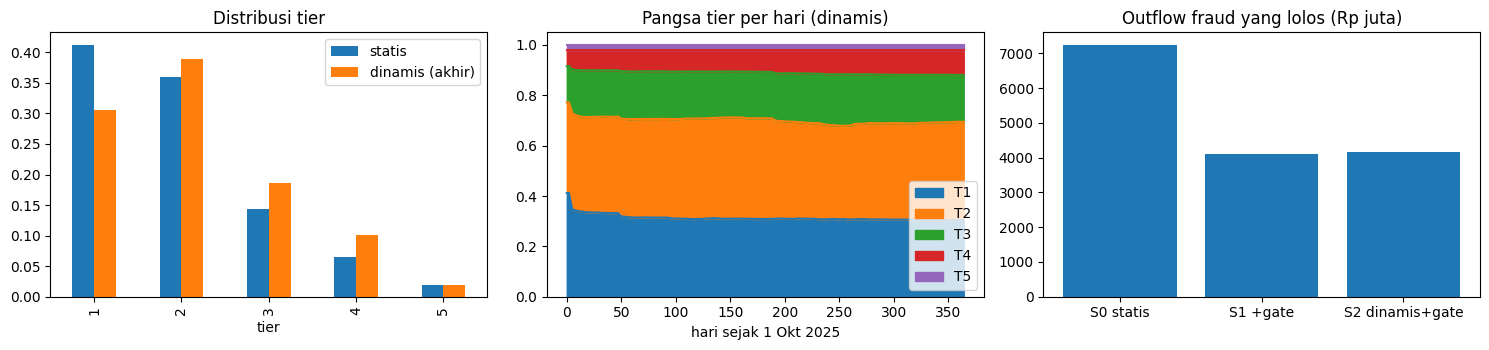

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tiers = pd.DataFrame({"statis": pd.Series(out["baseline_tier_share"]), "dinamis (akhir)": pd.Series(out["end_tier_share"])}).fillna(0); tiers.plot.bar(ax=ax[0], title="Distribusi tier"); ax[0].set_xlabel("tier")
th = ctx["tier_hist"][:, SM.T0:]; share = pd.DataFrame({f"T{k}": (th == k).mean(axis=0) for k in range(1, 6)}); share.plot.area(ax=ax[1], title="Pangsa tier per hari (dinamis)"); ax[1].set_xlabel("hari sejak 1 Okt 2025")
lab = ["S0 statis", "S1 +gate", "S2 dinamis+gate"]; ax[2].bar(lab, [s0["fraud_outflow"] / 1e6, s1["fraud_outflow"] / 1e6, s2["fraud_outflow"] / 1e6]); ax[2].set_title("Outflow fraud yang lolos (Rp juta)")
plt.tight_layout(); plt.show()

### Fairness hasil tier dan gesekan (§6.4: wilayah, gender, usia)
Proposal meminta distribusi skor *dan hasil tier* diperiksa per wilayah, gender, dan kelompok usia. Tabel membandingkan, per kelompok: persentase nasabah yang pernah naik tier, rata-rata perubahan tier, penolakan karena limit (statis vs dinamis), serta gesekan (hold dan step-up pada hari sah).
Perbedaan antar kelompok **tidak otomatis berarti bias**: komposisi tier awal dan pendapatan berbeda antar kelompok. Gunakan sebagai alat pemantauan; rasio terkecil/terbesar < 0,8 pada tingkat kenaikan patut diselidiki.

In [9]:
cu = pd.read_csv("data/sim/customers.csv").set_index("customer_id").loc[ctx["ids"]]
pc, th = ctx["per_cust"], ctx["tier_hist"][:, SM.T0:]
fd = pd.DataFrame({"gender": cu.gender.values, "usia": cu.age_band.values, "wilayah": cu.region.values, "baseline": ctx["baseline"], "naik": th.max(axis=1) > ctx["baseline"], "selisih_tier": th[:, -1] - ctx["baseline"],
                   "tolakan_statis": pc["declined_static"], "tolakan_dinamis": pc["declined_dynamic"], "hold_sah": pc["holds_legit"], "stepup_sah": pc["stepup_legit"]})
tabs = {}
for col in ("gender", "usia", "wilayah"):
    g = fd.groupby(col).agg(n=("naik", "size"), pct_naik=("naik", "mean"), rata2_selisih_tier=("selisih_tier", "mean"), baseline_rata2=("baseline", "mean"), tolakan_statis=("tolakan_statis", "mean"),
                            tolakan_dinamis=("tolakan_dinamis", "mean"), hold_sah=("hold_sah", "mean"), stepup_sah=("stepup_sah", "mean"))
    tabs[col] = g; display(g.round(3))
ratio = pd.Series({c: t[t.n >= 300].pct_naik.min() / t[t.n >= 300].pct_naik.max() for c, t in tabs.items()}); print("rasio tingkat kenaikan terkecil/terbesar (grup n >= 300):", ratio.round(2).to_dict())
rh = pd.Series({c: t[t.n >= 300].hold_sah.max() / max(t[t.n >= 300].hold_sah.min(), 1e-9) for c, t in tabs.items()}); print("rasio hold salah terbesar/terkecil:", rh.round(2).to_dict())

,n,pct_naik,rata2_selisih_tier,baseline_rata2,tolakan_statis,tolakan_dinamis,hold_sah,stepup_sah
gender,,,,,,,,
F,5044,0.321,0.217,1.928,2.400,1.622,0.086,1.901
M,4956,0.317,0.221,1.908,2.253,1.526,0.076,1.906


,n,pct_naik,rata2_selisih_tier,baseline_rata2,tolakan_statis,tolakan_dinamis,hold_sah,stepup_sah
usia,,,,,,,,
18-24,1676,0.230,0.165,1.530,1.257,0.779,0.092,1.696
25-34,3238,0.306,0.200,1.830,1.942,1.279,0.087,1.781
35-44,2490,0.339,0.233,2.046,2.686,1.867,0.070,1.949
45-54,1655,0.381,0.265,2.154,3.100,2.094,0.074,2.097
55+,941,0.360,0.264,2.163,3.245,2.315,0.081,2.231


,n,pct_naik,rata2_selisih_tier,baseline_rata2,tolakan_statis,tolakan_dinamis,hold_sah,stepup_sah
wilayah,,,,,,,,
Bali,299,0.318,0.201,1.953,2.201,1.522,0.090,1.977
Banten,761,0.335,0.213,1.936,2.390,1.633,0.076,1.854
DI Yogyakarta,300,0.340,0.240,1.920,2.777,1.840,0.063,1.800
DKI Jakarta,1492,0.280,0.181,1.946,2.200,1.593,0.074,1.937
Jawa Barat,1915,0.322,0.217,1.935,2.217,1.530,0.094,1.917
Jawa Tengah,1248,0.321,0.224,1.891,2.218,1.490,0.062,1.858
Jawa Timur,1456,0.321,0.229,1.894,2.332,1.591,0.084,1.949
Kalimantan Timur,333,0.366,0.285,1.910,2.676,1.649,0.111,2.000
Lampung,431,0.332,0.237,1.891,2.531,1.522,0.058,1.810


rasio tingkat kenaikan terkecil/terbesar (grup n >= 300): {'gender': 0.99, 'usia': 0.6, 'wilayah': 0.76}
rasio hold salah terbesar/terkecil: {'gender': 1.13, 'usia': 1.31, 'wilayah': 1.92}


## 4. Uji sensitivitas
Asumsi yang paling berpengaruh pada klaim dampak: keefektifan hold, tingkat penerimaan penawaran, dan parameter hysteresis/cooldown. Setiap baris menjalankan ulang simulasi (data dan model sama).

In [10]:
def kpi(o):
    a, b, c = o["S0_static"], o["S1_static_gate"], o["S2_dynamic_gate"]
    return {"penolakan sah turun %": 100 * (1 - c["declined_events"] / a["declined_events"]), "volume sah naik %": 100 * (c["legit_volume"] / a["legit_volume"] - 1),
            "fraud lolos S2 vs S1 %": 100 * (c["fraud_outflow"] / b["fraud_outflow"] - 1), "fraud turun S2 vs S0 %": 100 * (1 - c["fraud_outflow"] / a["fraud_outflow"]),
            "perubahan tier/nasabah-th": o["tier_changes_per_customer_year"], "nasabah naik %": 100 * o["customers_ever_increased"] / prep["n"]}
runs = {"dasar (diterima 70%, hold efektif 50%, hysteresis 14 hari, cooldown 7)": {}, "hysteresis 3 hari (literal proposal)": dict(policy=dict(lower_needed=3)),
        "hold efektif 25%": dict(hold_effectiveness=0.25), "hold efektif 100%": dict(hold_effectiveness=1.0),
        "penawaran diterima 40%": dict(accept_p=0.4), "penawaran diterima 90%": dict(accept_p=0.9),
        "hysteresis 30 hari": dict(policy=dict(lower_needed=30)),
        "cooldown 14 hari": dict(policy=dict(cooldown_days=14)), "tanpa step-down oleh gate": dict(policy=dict(gate_stepdown=False)),
        "lebih ketat: 9 bulan di tier sebelumnya": dict(policy=dict(months_at_prior_tier=9)), "lebih longgar: forecast > 40% cap tier bawah": dict(policy=dict(forecast_ratio=0.4))}
sens = pd.DataFrame({k: kpi(SM.run(prep, seed=1, **v)[0]) for k, v in runs.items()}).T; sens.round(2)

,penolakan sah turun %,volume sah naik %,fraud lolos S2 vs S1 %,fraud turun S2 vs S0 %,perubahan tier/nasabah-th,nasabah naik %
"dasar (diterima 70%, hold efektif 50%, hysteresis 14 hari, cooldown 7)",32.35,5.53,1.64,42.36,0.75,31.90
hysteresis 3 hari (literal proposal),29.68,5.08,1.23,42.59,1.02,31.90
hold efektif 25%,32.35,5.53,1.65,20.35,0.75,31.90
hold efektif 100%,32.35,5.53,1.44,86.38,0.75,31.90
penawaran diterima 40%,18.11,3.10,0.67,42.91,0.43,18.19
penawaran diterima 90%,41.63,7.17,1.90,42.21,0.97,41.19
hysteresis 30 hari,34.38,6.01,1.95,42.18,0.61,31.90
cooldown 14 hari,32.30,5.52,1.64,42.36,0.75,31.90
tanpa step-down oleh gate,32.68,5.59,6.11,39.82,0.74,31.90
lebih ketat: 9 bulan di tier sebelumnya,31.21,5.20,1.61,42.37,0.67,31.90


## 5. Kesimpulan
Ringkasan angka ada pada tabel di atas. Cara membacanya:
* **Klaim gesekan:** limit dinamis mengurangi transaksi sah yang ditolak karena limit pada sebagian besar sensitivitas, dan menambah volume sah yang terselesaikan.
* **Klaim keamanan:** pengurangan eksposur fraud berasal dari **fraud gate** (S1 vs S0); limit dinamis tidak menambah eksposur secara berarti (S2 vs S1), karena kenaikan hanya diberikan bila gate bersih. Cap rata-rata pada hari fraud pertama sedikit naik, sehingga ini perlu dipantau di pilot.
* **Aturan §6.3 (H) tertentu terlalu bising:** *night velocity* dan *outflow/balance* sebagai pemicu hold otomatis menahan sangat banyak hari sah dengan presisi rendah dibanding skor model. **Sudah diubah (G13):** keduanya menjadi pemicu step-up/blokir-kenaikan; hold hanya dari skor model.
* **Churn tier:** hysteresis 3 evaluasi harian terlalu pendek (lihat 'perubahan tier/nasabah-tahun'); **default disetel 14 hari (G14)**; varian literal proposal (3 hari) ada di tabel sensitivitas.
* **Keterbatasan:** open-loop (tanpa umpan balik perilaku), data sintetis, skorecard lemah (KS ~15 vs target 35), dan angka dampak sangat bergantung pada asumsi penerimaan penawaran dan keefektifan hold. Gunakan sebagai bukti konsep, bukan prakiraan finansial.